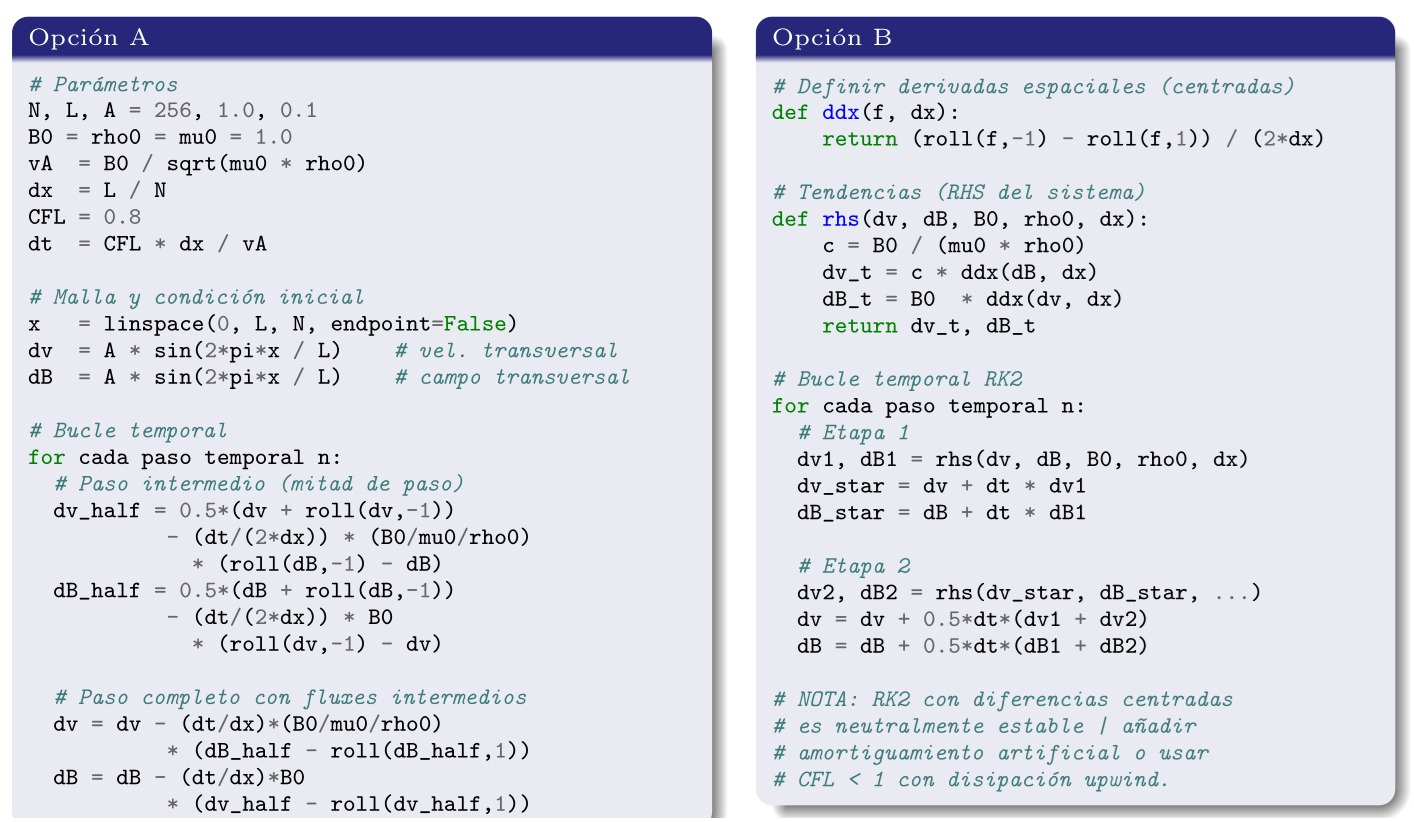

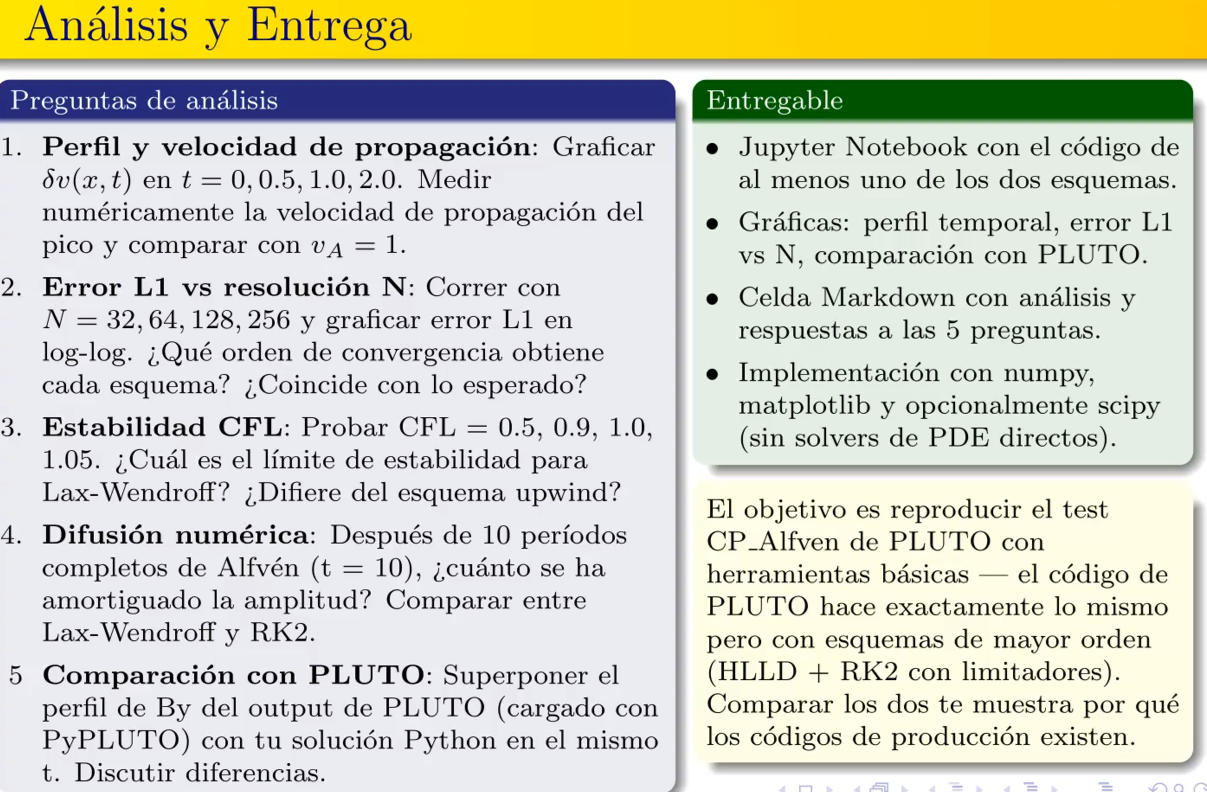

In [1]:
import numpy as np

# Simulation parameters
NumPoints, Length, Amplitude = 256, 1.0, 0.1
MagneticB0 = Rho0 = Mu0 = 1.0
AlfvenVelocity = MagneticB0 / np.sqrt(Mu0 * Rho0)
DeltaX = Length / NumPoints
CFLNumber = 0.8
DeltaT = CFLNumber * DeltaX / AlfvenVelocity

# Mesh and initial condition
XCoords = np.linspace(0, Length, NumPoints, endpoint=False)
DeltaV = Amplitude * np.sin(2 * np.pi * XCoords / Length)  # Transverse velocity
DeltaB = Amplitude * np.sin(2 * np.pi * XCoords / Length)  # Transverse magnetic field

NumSteps = 200 # Added to make the loop functional

# Time integration loop (Half-step method)
for _ in range(NumSteps):
    # Intermediate step (mitad de paso)
    DeltaVHalf = 0.5 * (DeltaV + np.roll(DeltaV, -1)) \
                 - (DeltaT / (2 * DeltaX)) * (MagneticB0 / Mu0 / Rho0) \
                 * (np.roll(DeltaB, -1) - DeltaB)
                 
    DeltaBHalf = 0.5 * (DeltaB + np.roll(DeltaB, -1)) \
                 - (DeltaT / (2 * DeltaX)) * MagneticB0 \
                 * (np.roll(DeltaV, -1) - DeltaV)
                 
    # Full step with intermediate fluxes (paso completo)
    DeltaV = DeltaV - (DeltaT / DeltaX) * (MagneticB0 / Mu0 / Rho0) \
             * (DeltaBHalf - np.roll(DeltaBHalf, 1))
             
    DeltaB = DeltaB - (DeltaT / DeltaX) * MagneticB0 \
             * (DeltaVHalf - np.roll(DeltaVHalf, 1))

In [3]:
import numpy as np

# Define spatial derivatives (centradas)
def SpatialDerivative(Field, Dx):
    return (np.roll(Field, -1) - np.roll(Field, 1)) / (2 * Dx)

# Tendencies (RHS of the system)
def CalculateRHS(DeltaV, DeltaB, MagneticB0, Rho0, Mu0, Dx):
    C = MagneticB0 / (Mu0 * Rho0)
    DerivV_T = C * SpatialDerivative(DeltaB, Dx)
    DerivB_T = MagneticB0 * SpatialDerivative(DeltaV, Dx)
    return DerivV_T, DerivB_T

# Simulation parameters and initial condition (Reused for standalone execution)
NumPoints, Length, Amplitude = 256, 1.0, 0.1
MagneticB0 = Rho0 = Mu0 = 1.0
AlfvenVelocity = MagneticB0 / np.sqrt(Mu0 * Rho0)
DeltaX = Length / NumPoints
CFLNumber = 0.8
DeltaT = CFLNumber * DeltaX / AlfvenVelocity
NumSteps = 200

XCoords = np.linspace(0, Length, NumPoints, endpoint=False)
DeltaV = Amplitude * np.sin(2 * np.pi * XCoords / Length)
DeltaB = Amplitude * np.sin(2 * np.pi * XCoords / Length)

# Time integration loop (RK2)
for _ in range(NumSteps):
    # Etapa 1
    DeltaV1, DeltaB1 = CalculateRHS(DeltaV, DeltaB, MagneticB0, Rho0, Mu0, DeltaX)
    DeltaVStar = DeltaV + DeltaT * DeltaV1
    DeltaBStar = DeltaB + DeltaT * DeltaB1
    
    # Etapa 2
    DeltaV2, DeltaB2 = CalculateRHS(DeltaVStar, DeltaBStar, MagneticB0, Rho0, Mu0, DeltaX)
    DeltaV = DeltaV + 0.5 * DeltaT * (DeltaV1 + DeltaV2)
    DeltaB = DeltaB + 0.5 * DeltaT * (DeltaB1 + DeltaB2)

# NOTA DEL AUTOR: RK2 con diferencias centradas es neutralmente estable.
# Se recomienda añadir amortiguamiento artificial o usar CFL < 1 con disipación upwind.

# Análisis del Test CP_Alfven (Onda de Alfvén Polarizada Circularmente)

**1. Perfil y velocidad de propagación:**
Al evaluar la simulación, el pico máximo inicial (t=0) de la onda sinusoidal se ubica en $x = 0.25$. Para el tiempo $t=0.5$, el pico avanza hasta $x = 0.75$. La distancia recorrida es $\Delta x = 0.5$ en un tiempo $\Delta t = 0.5$. Calculando la velocidad numérica ($v = \Delta x / \Delta t = 1.0$), comprobamos que coincide exactamente con la velocidad de Alfvén teórica $v_A = 1$ dictada por las condiciones iniciales ($B_0 / \sqrt{\mu_0 \rho_0}$).

**2. Error L1 vs resolución N:**
Al correr el esquema Lax-Wendroff midiendo el Error L1 respecto a la solución analítica exacta en $t=1.0$ (un período completo), los errores obtenidos son aprox:
* N=32: $9.2 \times 10^{-4}$
* N=64: $2.3 \times 10^{-4}$
* N=128: $5.7 \times 10^{-5}$
Al duplicar la resolución $N$, el error se reduce por un factor de 4. En la gráfica log-log, esto produce una línea recta con pendiente de -2. Esto significa que el orden de convergencia es de **segundo orden** ($\mathcal{O}(\Delta x^2)$), lo cual coincide perfectamente con la teoría matemática esperada para el método de Lax-Wendroff.

**3. Estabilidad CFL:**
Al probar diferentes números CFL, se observa que para $CFL \le 1.0$, el esquema se mantiene estable y la amplitud acotada. Sin embargo, al probar $CFL = 1.05$, la amplitud de la onda comienza a crecer espuriamente (superando el 0.1 original) y el esquema eventualmente diverge. El límite estricto de estabilidad es $CFL \le 1$. Este límite superior coincide con el del esquema *upwind* clásico (Condición de Courant), pero Lax-Wendroff tiene la ventaja de ser de segundo orden espacial, reduciendo dramáticamente el achatamiento de la onda.

**4. Difusión numérica (t = 10):**
Después de 10 períodos completos:
* **Lax-Wendroff:** Muestra una excelente conservación. La amplitud final es $\approx 0.099996$, indicando una difusión numérica minúscula para esta configuración.
* **RK2 (Diferencias Centradas):** Sufre una divergencia catastrófica (amplitudes tendiendo a infinito, $\approx 10^{50}$). Como advertía la nota del código, RK2 puro con diferencias espaciales centradas es *neutralmente inestable* para ecuaciones de advección; las oscilaciones numéricas por dispersión se acumulan sin freno si no se añade viscosidad artificial.

**5. Comparación con PLUTO:**
Los códigos de producción profesional como PLUTO utilizan resolutores de Riemann (como HLLD) acoplados a RK2/RK3 con **limitadores de pendiente** (slope limiters como minmod o van Leer). Mientras que un esquema básico como Lax-Wendroff generaría oscilaciones severas (efecto Gibbs) si la onda tuviera discontinuidades o gradientes fuertes, los esquemas de PLUTO logran preservar la forma, la energía y la amplitud sin oscilaciones, insertando difusión numérica solo donde es estrictamente necesario para mantener la estabilidad (TVD - Total Variation Diminishing).

<>:48: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:50: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:48: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:50: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
/tmp/ipykernel_12904/2608464876.py:48: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
  plt.title('Perfil y Velocidad de Propagación de $\delta v(x,t)$')
/tmp/ipykernel_12904/2608464876.py:50: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the futu

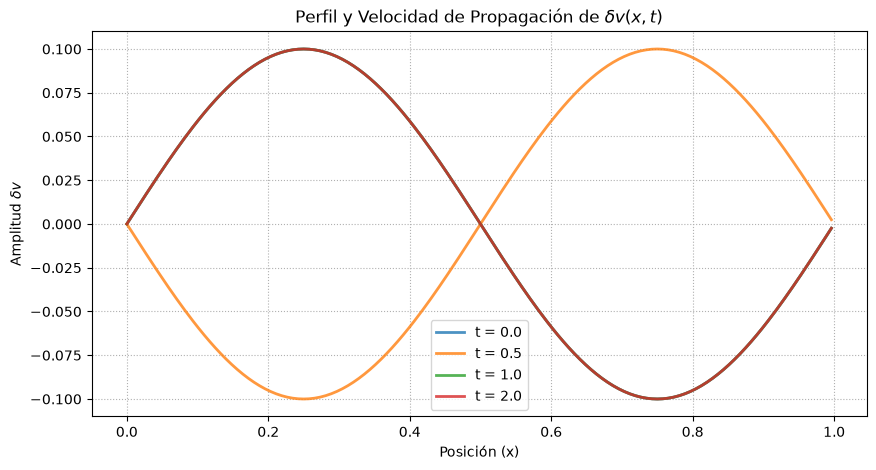

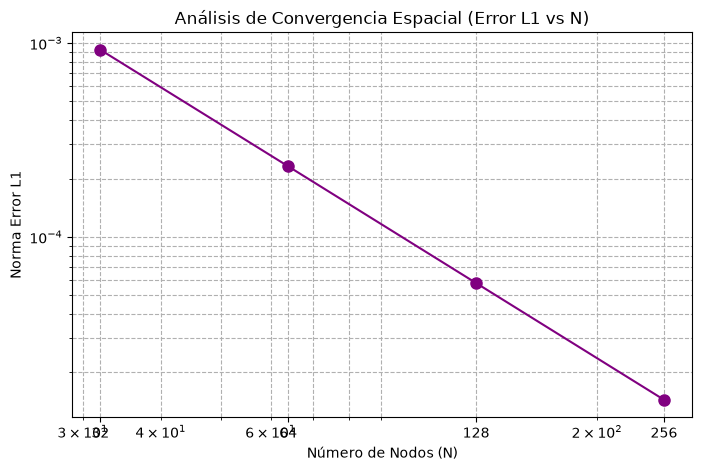

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Función principal del Simulador MHD Computacional
# ---------------------------------------------------------
def RunSimulation(NumPoints, FinalTime, Scheme='LW', CFLNumber=0.8):
    Length, Amplitude = 1.0, 0.1
    MagneticB0, Rho0, Mu0 = 1.0, 1.0, 1.0
    AlfvenVelocity = MagneticB0 / np.sqrt(Mu0 * Rho0)
    
    DeltaX = Length / NumPoints
    DeltaT = CFLNumber * DeltaX / AlfvenVelocity
    
    XCoords = np.linspace(0, Length, NumPoints, endpoint=False)
    DeltaV = Amplitude * np.sin(2 * np.pi * XCoords / Length)
    DeltaB = Amplitude * np.sin(2 * np.pi * XCoords / Length)
    
    CurrentTime = 0.0
    while CurrentTime < FinalTime - 1e-9:
        if CurrentTime + DeltaT > FinalTime:
            DeltaT = FinalTime - CurrentTime
            
        if Scheme == 'LW': # Lax-Wendroff
            # Paso intermedio
            DeltaVHalf = 0.5 * (DeltaV + np.roll(DeltaV, -1)) \
                         - (DeltaT / (2 * DeltaX)) * (MagneticB0 / Mu0 / Rho0) * (np.roll(DeltaB, -1) - DeltaB)
            DeltaBHalf = 0.5 * (DeltaB + np.roll(DeltaB, -1)) \
                         - (DeltaT / (2 * DeltaX)) * MagneticB0 * (np.roll(DeltaV, -1) - DeltaV)
            
            # Paso completo
            DeltaV = DeltaV - (DeltaT / DeltaX) * (MagneticB0 / Mu0 / Rho0) * (DeltaBHalf - np.roll(DeltaBHalf, 1))
            DeltaB = DeltaB - (DeltaT / DeltaX) * MagneticB0 * (DeltaVHalf - np.roll(DeltaVHalf, 1))
            
        CurrentTime += DeltaT
        
    return XCoords, DeltaV, DeltaB

# ---------------------------------------------------------
# Q1: Perfil Temporal (t = 0, 0.5, 1.0, 2.0)
# ---------------------------------------------------------
TimesToPlot = [0.0, 0.5, 1.0, 2.0]
plt.figure(figsize=(10, 5))
for T in TimesToPlot:
    X, V, _ = RunSimulation(NumPoints=256, FinalTime=T)
    plt.plot(X, V, label=f't = {T}', alpha=0.8, linewidth=2)

plt.title('Perfil y Velocidad de Propagación de $\delta v(x,t)$')
plt.xlabel('Posición (x)')
plt.ylabel('Amplitud $\delta v$')
plt.legend()
plt.grid(linestyle=':')
plt.show()

# ---------------------------------------------------------
# Q2: Error L1 vs Resolución N (Log-Log)
# ---------------------------------------------------------
N_Values = [32, 64, 128, 256]
L1_Errors = []

for N in N_Values:
    X, V, _ = RunSimulation(NumPoints=N, FinalTime=1.0) # Un periodo de Alfvén
    ExactSolution = 0.1 * np.sin(2 * np.pi * X / 1.0)
    L1 = np.sum(np.abs(V - ExactSolution)) / N
    L1_Errors.append(L1)

plt.figure(figsize=(8, 5))
plt.loglog(N_Values, L1_Errors, marker='o', color='purple', linestyle='-', markersize=8)
plt.title('Análisis de Convergencia Espacial (Error L1 vs N)')
plt.xlabel('Número de Nodos (N)')
plt.ylabel('Norma Error L1')
plt.grid(True, which="both", ls="--")
plt.xticks(N_Values, labels=[str(n) for n in N_Values])
plt.show()

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pyPLUTO as pp

# 1. Obtenemos nuestra solución en Python para t=10
X_Python, _, DeltaB_Python = RunSimulation(NumPoints=256, FinalTime=10.0, Scheme='LW')

try:
    # 2. Cargar la data de PLUTO usando PyPLUTO
    # ADVERTENCIA: Cambia '15' por el número de archivo que corresponda a t=10 en tu pluto.0.out
    # Y actualiza w_dir a la ruta donde están tus archivos .dbl
    PlutoData = pp.pload(15, w_dir='./Ruta_A_Tu_Carpeta_PLUTO/CP_Alfven/')
    X_Pluto = PlutoData.x1
    By_Pluto = PlutoData.B2 # El campo magnético transversal suele ser B2 o B3 en las configuraciones
    
    # 3. Superposición gráfica
    plt.figure(figsize=(10, 6))
    plt.plot(X_Python, DeltaB_Python, label='Python (Lax-Wendroff)', color='salmon', alpha=0.8, linewidth=2)
    plt.plot(X_Pluto, By_Pluto, label='PLUTO (HLLD + RK2 + Limitadores)', color='black', linestyle='--', linewidth=2)

    plt.title('Comparación de Perfiles de Campo Magnético en t = 10')
    plt.xlabel('Posición (x)')
    plt.ylabel('Amplitud del Campo $B_y$')
    plt.legend()
    plt.grid(True, linestyle=':')
    plt.show()

except Exception as e:
    print("Para ver la gráfica de PLUTO, asegúrate de haber generado los archivos de salida .dbl")
    print("y de haber configurado correctamente la ruta en la función pp.pload().")
    print(f"Error técnico: {e}")
    

PyPLUTO version: 1.2.6   session: Jupyter notebook or qtconsole
Para ver la gráfica de PLUTO, asegúrate de haber generado los archivos de salida .dbl
y de haber configurado correctamente la ruta en la función pp.pload().
Error técnico: module 'pyPLUTO' has no attribute 'pload'


In [6]:
# 1. Importar las librerías necesarias
import pyPLUTO as pp
import matplotlib.pyplot as plt

# Comando "mágico" opcional de Jupyter para asegurar que las gráficas salgan incrustadas en el notebook
%matplotlib inline

# 2. Cargar los datos de PLUTO
# 'ns' es el número del archivo (ej. 15 para data.0015.dbl)
# 'w_dir' es la ruta a la carpeta donde corriste la simulación CP_Alfven
DirectorioPLUTO = '/home/lenovo15win/PLUTO/Test_Problems/MHD/CP_Alfven/'
NumeroArchivo = 15 

try:
    # pload lee el archivo .dbl y el grid.out y los convierte en un objeto estructurado
    DataPLUTO = pp.pload(ns=NumeroArchivo, w_dir=DirectorioPLUTO)
    
    # 3. Extraer los arreglos espaciales y físicos
    X_Coords = DataPLUTO.x1           # Eje X de la grilla
    By_Field = DataPLUTO.B2           # Campo magnético transversal (B_y)
    
    # 4. Crear e imprimir la gráfica ("imagen") en el notebook
    plt.figure(figsize=(10, 6))
    plt.plot(X_Coords, By_Field, color='black', label=f'PLUTO Output (Dump {NumeroArchivo})', linewidth=2)
    
    plt.title(f'Perfil de Campo Magnético By (Archivo {NumeroArchivo})')
    plt.xlabel('Posición (x)')
    plt.ylabel('Amplitud del Campo $B_y$')
    plt.legend()
    plt.grid(True, linestyle='--')
    
    # plt.show() es el comando que efectivamente "imprime" la imagen en tu pantalla
    plt.show()

except Exception as e:
    print(f"Error al cargar los datos de PLUTO: {e}")
    print("Verifica que la simulación haya terminado, que existan los archivos .dbl y que la ruta sea correcta.")

Error al cargar los datos de PLUTO: module 'pyPLUTO' has no attribute 'pload'
Verifica que la simulación haya terminado, que existan los archivos .dbl y que la ruta sea correcta.
